<a href="https://colab.research.google.com/github/alexbedoni95-cpu/Analisi-Climatica-UE-e-Modellazione-Predittiva-2035-Progetto-Finale-EEA-/blob/main/Progetto_finale_aulab_richiesta_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Load the CSV file into a pandas DataFrame
df = pd.read_csv('/content/Renewable_Electricity_Production_Dataset.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,Country and area,1990,1991,1992,1993,1994,1995,1996,1997,1998,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,Afghanistan,67.73,67.98,67.99,68.35,68.70,69.04,70.37,72.39,74.44,...,85.32,86.07,86.15,84.70,NaN,NaN,NaN,NaN,NaN,NaN
1,Albania,87.61,95.07,95.89,95.12,96.62,95.24,96.63,96.99,97.10,...,100.00,100.00,100.00,100.78,100.0,99.74,99.71,100.00,99.79,100.00
2,Algeria,0.84,1.69,1.09,1.82,0.83,0.98,0.63,0.35,0.42,...,0.40,0.32,0.25,0.84,NaN,NaN,NaN,NaN,NaN,NaN
3,Andorra,100.0,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,88.98,86.87,84.85,83.82,84.5,83.92,83.95,83.74,83.35,83.34
4,Angola,86.21,82.66,88.70,93.68,93.72,93.75,89.98,76.35,80.42,...,53.18,53.18,56.12,71.40,NaN,NaN,NaN,NaN,NaN,NaN


### Paesi dell'Unione Europea che utilizzano maggiormente le Energie Rinnovabili per l'elettricità nel 2023

Per prima cosa, definisco un elenco di paesi membri dell'UE e filtro il DataFrame per l'anno 2023 e per questi paesi.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Assicurati che pandas sia importato per pd.melt

# Lista dei paesi membri dell'Unione Europea (aggiornata al 2023)
eu_countries = [
    'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia',
    'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece',
    'Hungary', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg',
    'Malta', 'Netherlands', 'Poland', 'Portugal', 'Romania', 'Slovakia',
    'Slovenia', 'Spain', 'Sweden'
]

# Trasforma il DataFrame da formato wide a long
df_melted = df.melt(id_vars=['Country and area'], var_name='Year', value_name='Value')

# Rinomina la colonna 'Country and area' in 'Country'
df_melted = df_melted.rename(columns={'Country and area': 'Country'})

# Converti la colonna 'Year' a tipo numerico, gestendo errori
df_melted['Year'] = pd.to_numeric(df_melted['Year'], errors='coerce')

# Rimuovi i valori NaN dalla colonna 'Value' e 'Year' dopo la conversione
df_melted = df_melted.dropna(subset=['Value', 'Year'])

# Converti 'Year' in intero dopo aver rimosso i NaN
df_melted['Year'] = df_melted['Year'].astype(int)

# Filtra i dati per l'anno 2023
df_2023 = df_melted[df_melted['Year'] == 2023]

# Filtra per i paesi dell'Unione Europea
df_eu_2023 = df_2023[df_2023['Country'].isin(eu_countries)]

# Assumendo che la colonna 'Value' rappresenti la produzione di energia elettrica in TWh o un'unità simile.
# Raggruppa per paese e somma i valori di produzione di energia rinnovabile
eu_renewable_production = df_eu_2023.groupby('Country')['Value'].sum().reset_index()

# Ordina in ordine decrescente e seleziona i primi 10 paesi
top_eu_countries = eu_renewable_production.sort_values(by='Value', ascending=False).head(10)

display(top_eu_countries)

,Country,Value
17,Luxembourg,78.47
0,Austria,70.48
16,Lithuania,68.26
15,Latvia,59.84
3,Croatia,57.59
26,Sweden,50.47
6,Denmark,49.88
22,Romania,37.52
21,Portugal,35.88
25,Spain,31.31


Ora visualizzo i risultati con un grafico a barre orizzontali.

/tmp/ipykernel_680/1786119303.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Value', y='Country', data=top_eu_countries, palette='viridis')


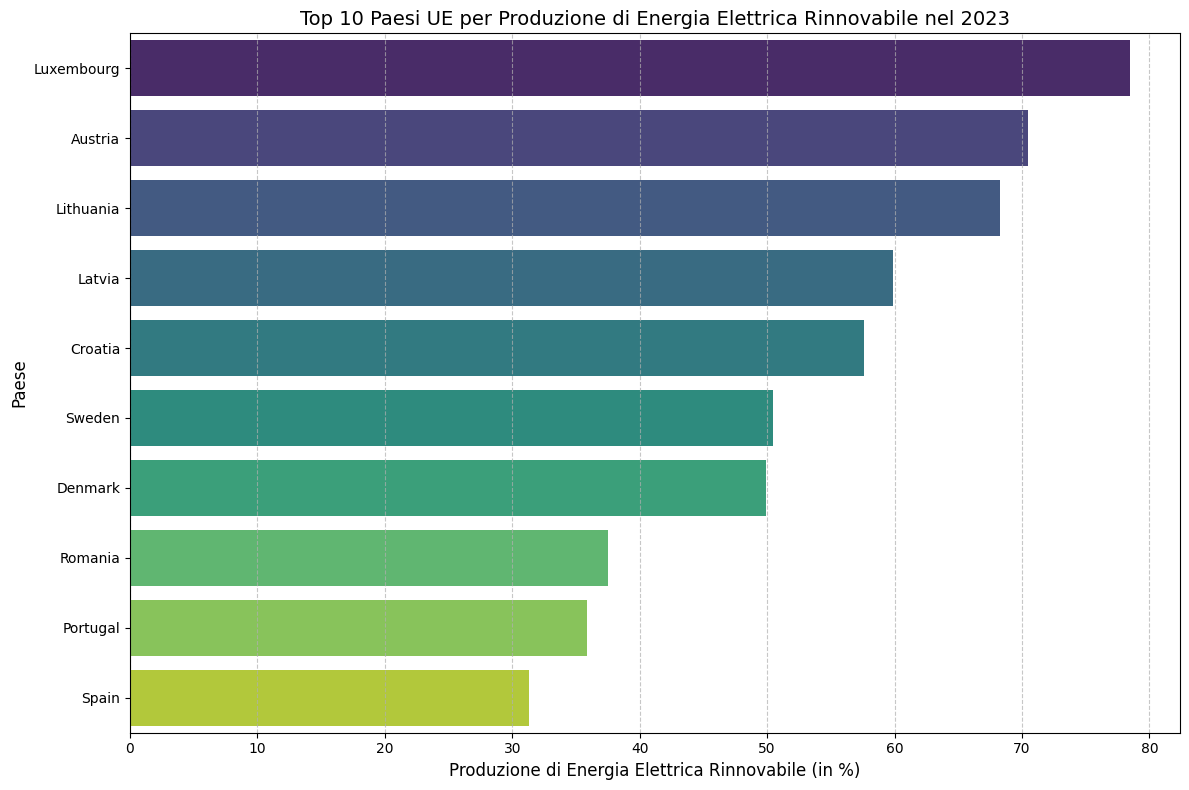

In [ ]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Value', y='Country', data=top_eu_countries, palette='viridis', hue='Country', legend=False)
plt.xlabel('Produzione di Energia Elettrica Rinnovabile (in %)', fontsize=12)
plt.ylabel('Paese', fontsize=12)
plt.title('Top 10 Paesi UE per Produzione di Energia Elettrica Rinnovabile nel 2023', fontsize=14)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()